# Part A — Local Contrast Enhancement (LCE) preprocessing pipeline

A classical local contrast enhancement pipeline for cervical colposcopy
images.

## What "Local Contrast Enhancement" means here

The pipeline applies **CLAHE (Contrast-Limited Adaptive Histogram
Equalization)** to the L* channel of the CIELAB representation:

1. The RGB frame is converted to LAB. CLAHE equalises the L* histogram
   *locally* over a `tile x tile` grid of contextual regions, and the clip
   limit bounds how much any single histogram bin may be amplified — that
   clip is the guard against amplifying sensor noise in flat regions.
2. a* and b* are passed through untouched, so hue and colour balance are
   preserved; only local lightness contrast changes.
3. The enhanced L* is merged back with the original a*/b* and converted to
   uint8 RGB.

Everything in this notebook is standard classical image processing (OpenCV
`createCLAHE`). There is no quantisation, no bit allocation, no random
component: the mapping is fully deterministic for a fixed configuration.

## Pipeline overview

* Step 1 — Load + resize to 200x200 (single source of truth for preprocessing).
* Step 2 — LCE: CLAHE on L* (LAB), clip limit 2.0, 8x8 tiles, chroma preserved.

## Output

The pipeline returns an **enhanced image** (uint8 RGB, same shape as the
input). It is NOT a compression scheme: every output pixel keeps the full
8-bit depth and the output PNG is approximately the same size as the input
PNG. The technique is therefore evaluated as an image-enhancement technique
(distortion, structure preservation, diagnostics) against the ORIGINAL
image.

## What this notebook does NOT claim

* It does NOT produce a compressed byte stream.
* It does NOT compare techniques against each other (that requires the
  multi-patient notebook).
* It does NOT demonstrate a clinical benefit on this single patient.


In [1]:
# ============================================================
# Cell 1.1 — Combined imports & global setup
# ============================================================
import os, glob, random, warnings, platform

import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

import pandas as pd
from scipy import ndimage
from scipy.ndimage import gaussian_filter

warnings.filterwarnings('ignore')

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100

# Output directory for results / CSV / figure artefacts
# Relative path so the notebook is portable across Windows / Linux / macOS.
SAVE_DIR = 'results'
os.makedirs(SAVE_DIR, exist_ok=True)

print(f"\nLCE Validation Pipeline — Python {platform.python_version()}")
print(f"NumPy {np.__version__} | Pandas {pd.__version__} | OpenCV {cv2.__version__}")
print(f"Random seed: {SEED}")
print(f"Output directory: {SAVE_DIR}")
print("All imports OK.")



LCE Validation Pipeline — Python 3.10.20
NumPy 2.2.6 | Pandas 2.3.3 | OpenCV 4.11.0
Random seed: 42
Output directory: results
All imports OK.


In [2]:
# ============================================================
# Cell 2 -- Configuration
#   Single-class invasive carcinoma dataset.
#   Expected layout (configurable below):
#       <DATASET_ROOT>/<INVASIVE_DIR>/images/*.jpg
#       <DATASET_ROOT>/<INVASIVE_DIR>/<MASKS_SUBDIR>/*.png
# ============================================================

# ---- Image size ----
IMG_SIZE = 200

# ---- Data ----
# Use forward slashes -- works on both Windows and Linux/macOS.
DATASET_ROOT   = "C:/CER/dataset"   # <-- your dataset root
INVASIVE_DIR   = "invasive cancer"  # <-- single class folder (note the space)
MASKS_SUBDIR   = "masks"            # set "" if masks live directly under invasive cancer/
CLASSES        = ["invasive cancer"]  # only one class

# ---- Local Contrast Enhancement (LCE, Step 2) ----
# CLAHE is applied to the L* channel of the LAB representation:
#   * LCE_CLIP_LIMIT bounds the amplification of any histogram bin, which
#     is the guard against amplifying sensor noise in flat regions;
#   * LCE_TILE_GRID sets the local context size: smaller tiles = stronger
#     local adaptation, larger tiles = closer to global equalisation;
#   * a* / b* are NOT touched, so hue and colour balance are preserved.
# The mapping is fully deterministic: CLAHE contains no random component,
# so re-running with the same configuration reproduces the same output.
LCE_CLIP_LIMIT  = 2.0
LCE_TILE_GRID   = (8, 8)

# ---- Validation batch (Part B) ----
# None = validate every loaded image.
SUBSET_PER_CLASS = None

print(f"Configuration OK  |  classes={CLASSES}  |  img={IMG_SIZE}x{IMG_SIZE}")
print(f"  LCE: CLAHE on L* (LAB)  |  clip limit={LCE_CLIP_LIMIT}  |  "
      f"tile grid={LCE_TILE_GRID[0]}x{LCE_TILE_GRID[1]}  |  a*/b* preserved")
print(f"  deterministic = True (no RNG anywhere in the pipeline)")
print(f"  validation batch = all loaded images (subset_per_class={SUBSET_PER_CLASS})")
print(f"  metrics = 11 (PSNR (dB), SSIM, dE76, a* correlation, |a*| shift,")
print(f"           Vessel Dice, Edge IoU, Sharpness ratio, Noise ratio,")
print(f"           Saturation ratio, Luma bits) computed inside the FOV")
print(f"           against the ORIGINAL image (original = ground truth).")


Configuration OK  |  classes=['invasive cancer']  |  img=200x200
  LCE: CLAHE on L* (LAB)  |  clip limit=2.0  |  tile grid=8x8  |  a*/b* preserved
  deterministic = True (no RNG anywhere in the pipeline)
  validation batch = all loaded images (subset_per_class=None)
  metrics = 11 (PSNR (dB), SSIM, dE76, a* correlation, |a*| shift,
           Vessel Dice, Edge IoU, Sharpness ratio, Noise ratio,
           Saturation ratio, Luma bits) computed inside the FOV
           against the ORIGINAL image (original = ground truth).


In [3]:
# ============================================================
# Cell 1.3 -- preprocess + load_dataset
#            (diverse synthetic fallback + SYNTHETIC_MODE flag)
# ============================================================
def preprocess_image(img_bgr, size=IMG_SIZE):
    """BGR -> RGB -> resize. Single source of truth."""
    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (size, size))
    return img


def _find_lesion_masks(folder, stem, size):
    """Look up a clinician mask for the given image stem. Returns (mask, hit_path)
    or (None, None) if no match."""
    for mext in (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"):
        cand = os.path.join(folder, stem + mext)
        if os.path.isfile(cand):
            m = cv2.imread(cand, cv2.IMREAD_GRAYSCALE)
            if m is not None:
                m = cv2.resize(m, (size, size), interpolation=cv2.INTER_NEAREST)
                return (m > 127).astype(bool), cand
    return None, None


def load_dataset(root, classes, size=IMG_SIZE, subset_per_class=None,
                 masks_subdir="masks"):
    """Load images from <root>/<class>/images/ (or <root>/<class>/), resize.
    Case-insensitive dedupe by filename so the same physical file is never
    loaded twice on Windows / macOS.

    If a sibling `masks_subdir` folder exists, lesion masks are loaded
    matched by filename stem (e.g. `images/abc.jpg` -> `masks/abc.png`).
    Missing masks default to an all-False mask (H, W) bool and are
    reported. Returns (X, y, paths, masks, n_with_mask, n_dedup).
    """
    X, y, paths, masks = [], [], [], []
    n_with_mask_total = 0
    n_dedup_total = 0
    for cls in classes:
        folder = os.path.join(root, cls)
        if not os.path.isdir(folder):
            print(f"  [warn] folder not found: {folder}")
            continue
        img_folder = os.path.join(folder, "images")
        if not os.path.isdir(img_folder):
            img_folder = folder
        raw = []
        for ext in ("*.jpg", "*.jpeg", "*.png"):
            raw.extend(glob.glob(os.path.join(img_folder, ext)))
        seen, files = set(), []
        n_dup_this = 0
        for p in sorted(raw):
            key = os.path.normpath(p).lower()
            if key in seen:
                n_dup_this += 1
                continue
            seen.add(key)
            files.append(p)
        n_dedup_total += n_dup_this
        if subset_per_class:
            files = files[:subset_per_class]
        mask_folder = os.path.join(folder, masks_subdir) if masks_subdir else None
        n_with_mask = 0
        for p in files:
            img = cv2.imread(p)
            if img is None:
                continue
            img = preprocess_image(img, size=size)
            stem = os.path.splitext(os.path.basename(p))[0]
            msk = None
            if mask_folder and os.path.isdir(mask_folder):
                msk, _ = _find_lesion_masks(mask_folder, stem, size)
                if msk is not None:
                    n_with_mask += 1
            if msk is None:
                msk = np.zeros((size, size), dtype=bool)
            X.append(img); y.append(cls); paths.append(p); masks.append(msk)
        n_with_mask_total += n_with_mask
        print(f"  {cls:>20}: {len(files):>4} images | masks matched: {n_with_mask}/{len(files)}  "
              f"| deduped: {n_dup_this}")
        # If a masks/ folder exists but 0 masks matched, warn the user.
        if mask_folder and os.path.isdir(mask_folder) and n_with_mask == 0 and len(files) > 0:
            print(f"    [warn] masks/ folder found at {mask_folder} but 0/{len(files)} "
                  f"images matched. Check that mask filename stems match image stems.")
    if not X:
        empty = (np.zeros((0, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8),
                 np.array([]), [],
                 np.zeros((0, IMG_SIZE, IMG_SIZE), dtype=bool),
                 0, n_dedup_total)
        return empty
    return (np.array(X, dtype=np.uint8), np.array(y), paths,
            np.array(masks, dtype=bool), n_with_mask_total, n_dedup_total)


def make_synthetic_image_and_mask(H=200, W=200, seed=None):
    """Diverse synthetic 200x200 RGB histology-like image AND its lesion mask.

    Returns (image_uint8, mask_bool). The mask is True inside the same
    circles that were drawn into the image, so mask-vs-GT
    evaluations have a real target.
    """
    rng = np.random.RandomState(seed)
    grad_dir = rng.choice(['h', 'v', 'd1', 'd2'])
    base = rng.uniform(35, 80)
    slope = rng.uniform(15, 40)
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
    if grad_dir == 'h':
        bg = base + slope * xx / W
    elif grad_dir == 'v':
        bg = base + slope * yy / H
    elif grad_dir == 'd1':
        bg = base + slope * (xx + yy) / (W + H)
    else:
        bg = base + slope * (xx - yy + W) / (2 * W)
    img = np.stack([bg, bg, bg], axis=-1)
    n_lesions = rng.randint(1, 4)
    yy2, xx2 = np.ogrid[:H, :W]
    mask = np.zeros((H, W), dtype=bool)
    for _ in range(n_lesions):
        cx = rng.randint(W // 5, 4 * W // 5)
        cy = rng.randint(H // 5, 4 * H // 5)
        r  = rng.randint(15, 50)
        disk = ((yy2 - cy) ** 2 + (xx2 - cx) ** 2 <= r ** 2)
        lr = rng.randint(180, 240)
        lg = rng.randint(120, 200)
        lb = rng.randint(60, 140)
        img[disk, 0] = lr; img[disk, 1] = lg; img[disk, 2] = lb
        mask |= disk
    texture = gaussian_filter(rng.uniform(-1, 1, (H, W)), sigma=8) * 20
    img = img + texture[..., None]
    noise = rng.randint(0, 15, (H, W, 3), dtype=np.uint8)
    return np.clip(img.astype(np.int32) + noise, 0, 255).astype(np.uint8), mask


# Load (or build synthetic fallback)
print("Loading dataset ...")
load_out = load_dataset(
    DATASET_ROOT, CLASSES,
    size=IMG_SIZE,
    subset_per_class=SUBSET_PER_CLASS,
)
X_raw, y_raw, paths_raw, masks_raw, n_with_mask, n_dedup = load_out
print(f"\nTotal images : {len(X_raw)} | masks matched: {n_with_mask}/{len(X_raw)} "
      f"| deduped (skipped duplicates): {n_dedup}")
if len(X_raw) > 0:
    SYNTHETIC_MODE = False
    print(f"Class counts : {dict(zip(*np.unique(y_raw, return_counts=True)))}")
    print(f"SYNTHETIC_MODE = {SYNTHETIC_MODE}")
else:
    SYNTHETIC_MODE = True
    print("\n*** No images found at:", DATASET_ROOT,
          "-- building DIVERSE synthetic fallback (10 imgs/class, with lesion masks).")
    X_synth, y_synth, m_synth = [], [], []
    for cls_idx, cls in enumerate(CLASSES):
        for k in range(10):
            img, msk = make_synthetic_image_and_mask(seed=SEED + cls_idx * 1000 + k)
            X_synth.append(img); y_synth.append(cls); m_synth.append(msk)
    X_raw = np.stack(X_synth).astype(np.uint8)
    y_raw = np.array(y_synth)
    paths_raw = [f"<synthetic>/{c}/{i}.png" for c, i in zip(y_raw, range(len(y_raw)))]
    masks_raw = np.stack(m_synth).astype(bool)
    class_color_offset = {'invasive cancer': (25, 15, 10)}
    for i, cls in enumerate(y_raw):
        dr, dg, db = class_color_offset.get(cls, (0, 0, 0))
        X_raw[i] = np.clip(X_raw[i].astype(np.int32) + np.array([dr, dg, db]),
                           0, 255).astype(np.uint8)
    print(f"[fallback] Synthetic dataset ready: {len(X_raw)} images, "
          f"{int(masks_raw.any((1,2)).sum())}/{len(masks_raw)} with lesion masks "
          f"(SYNTHETIC_MODE=True).")


Loading dataset ...
       invasive cancer:  128 images | masks matched: 0/128  | deduped: 0

Total images : 128 | masks matched: 0/128 | deduped (skipped duplicates): 0
Class counts : {np.str_('invasive cancer'): np.int64(128)}
SYNTHETIC_MODE = False


In [4]:
# ============================================================
# Cell 2.1 -- Local Contrast Enhancement (CLAHE on L*, LAB)
# ============================================================
def local_contrast_enhance(img_rgb, clip_limit=None, tile_grid=None):
    """CLAHE on the L* channel of LAB; a*/b* passed through untouched.

    Parameters
    ----------
    img_rgb : uint8 RGB array (H, W, 3)
    clip_limit : float or None
        None -> LCE_CLIP_LIMIT. Contrast-limited threshold; bounds how far
        any histogram bin may be amplified (noise-amplification guard).
    tile_grid : (int, int) or None
        None -> LCE_TILE_GRID. Size of the local tile grid for the
        adaptive equalisation.

    Returns
    -------
    uint8 RGB array, same shape as the input.
    """
    clip_limit = LCE_CLIP_LIMIT if clip_limit is None else clip_limit
    tile_grid  = LCE_TILE_GRID  if tile_grid  is None else tuple(tile_grid)
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    l_chan, a_chan, b_chan = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=float(clip_limit),
                            tileGridSize=tuple(tile_grid))
    l_enh = clahe.apply(l_chan)
    out = cv2.cvtColor(cv2.merge([l_enh, a_chan, b_chan]), cv2.COLOR_LAB2RGB)
    return out


# Validator-facing wrapper: same signature convention as the validator
# suite (params dict + per-image seed accepted for API compatibility; both
# are ignored because CLAHE is deterministic and uses fixed module-level
# configuration).
LCE_DEFAULTS = {}

def lce_enhance(img, params=None, seed=0):
    """LCE preprocessing, exposed to the Step 4 validator.

    Signature: lce_enhance(img_uint8_RGB, params_dict, seed) -> uint8 RGB.
    """
    return local_contrast_enhance(img)


# Determinism smoke test on the first image
_sm1 = lce_enhance(X_raw[0], LCE_DEFAULTS, seed=12345)
_sm2 = lce_enhance(X_raw[0], LCE_DEFAULTS, seed=999)
assert _sm1.shape == X_raw[0].shape and _sm1.dtype == np.uint8, \
    f"lce_enhance smoke test failed: got {_sm1.shape} {_sm1.dtype}"
assert np.array_equal(_sm1, _sm2), "lce_enhance is not deterministic"
print(f"lce_enhance() ready  |  LCE_DEFAULTS = {LCE_DEFAULTS}")
print(f"  smoke test on image 0: shape={_sm1.shape} dtype={_sm1.dtype}  "
      f"mean|diff|={np.abs(_sm1.astype(int) - X_raw[0].astype(int)).mean():.3f}  "
      f"deterministic=True")


lce_enhance() ready  |  LCE_DEFAULTS = {}
  smoke test on image 0: shape=(200, 200, 3) dtype=uint8  mean|diff|=18.729  deterministic=True


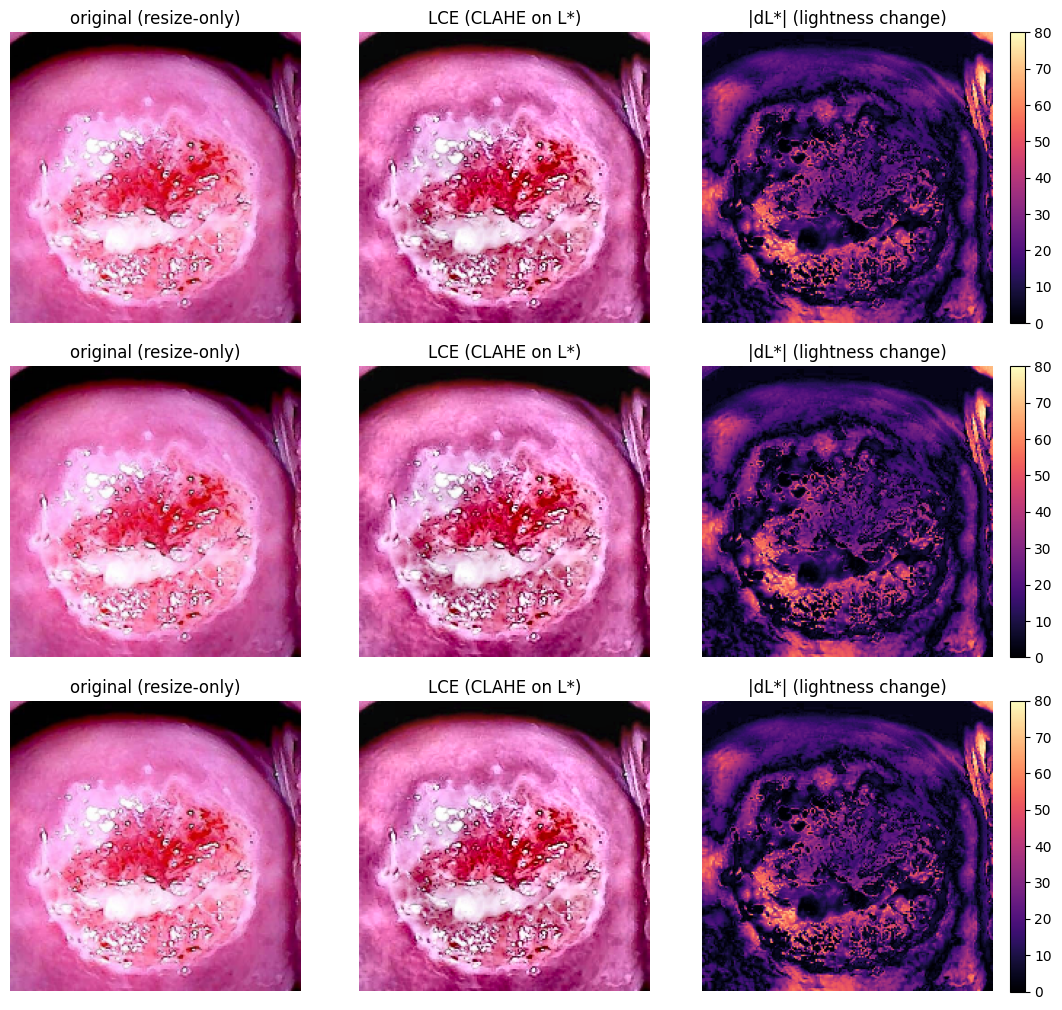

Saved results\lce_before_after.png


In [5]:
# ============================================================
# Cell 1.4 -- LCE before/after visualisation
# ============================================================
def show_lce_effect(n_show=3):
    """Original vs LCE vs |dL*| map for the first `n_show` images."""
    n_show = min(n_show, len(X_raw))
    if n_show == 0:
        print("No images to visualise.")
        return
    fig, axes = plt.subplots(n_show, 3, figsize=(11, 3.4 * n_show))
    axes = np.atleast_2d(axes)
    for r in range(n_show):
        orig = X_raw[r]
        proc = lce_enhance(orig)
        lab_o = cv2.cvtColor(orig, cv2.COLOR_RGB2LAB)[..., 0].astype(np.int16)
        lab_p = cv2.cvtColor(proc, cv2.COLOR_RGB2LAB)[..., 0].astype(np.int16)
        dl = np.abs(lab_p - lab_o)
        axes[r, 0].imshow(orig)
        axes[r, 0].set_title("original (resize-only)")
        axes[r, 1].imshow(proc)
        axes[r, 1].set_title("LCE (CLAHE on L*)")
        im = axes[r, 2].imshow(dl, cmap='magma', vmin=0,
                               vmax=max(10, int(dl.max())))
        axes[r, 2].set_title("|dL*| (lightness change)")
        plt.colorbar(im, ax=axes[r, 2], fraction=0.046)
        for c in range(3):
            axes[r, c].axis('off')
    fig.tight_layout()
    out = os.path.join(SAVE_DIR, "lce_before_after.png")
    fig.savefig(out, dpi=110)
    plt.show()
    print(f"Saved {out}")

show_lce_effect(3)


# Part B — Validation: 11 metrics vs the ORIGINAL image

Descriptive, single-patient validation. The frames are NOT independent
(dHash clustering below groups near-duplicate frames into clusters). No
p-values, no robustness or population claims.

**Technique:** LCE (CLAHE on L*, LAB; clip limit 2.0, 8x8 tiles).

**Ground truth:** the ORIGINAL resize-only image. Every metric is computed
per image, inside the field-of-view (FOV) mask only, against that original.

**Metrics (11):**

| # | Metric | Group | Better |
|---|--------|-------|--------|
| m1 | PSNR (dB) | fidelity | up |
| m2 | SSIM | fidelity | up |
| m3 | ΔE76 (CIE76) | colour | down |
| m4 | a* correlation | colour | up |
| m5 | \|a*\| shift | colour | down |
| m6 | Vessel Dice | structure | up |
| m7 | Edge IoU | structure | up |
| m8 | Sharpness ratio (out/in) | quality | neutral |
| m9 | Noise ratio (out/in) | quality | down |
| m10 | Saturation ratio (out/in) | quality | neutral |
| m11 | Luma bits (output luma histogram entropy, bits/px) | cost | descriptive |

**Outputs:** per-image CSVs, a cluster-weighted summary CSV, a
before/after figure (Part A) and an 11-metric summary bar chart. Tables
only otherwise — no other plots.


In [6]:
# ============================================================
# Step 4.1 -- Freeze inputs: FOV masks, cluster ids, image ids.
# ============================================================
def _dhash_step4(gray):
    g = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA).astype(np.int16)
    return (g[:, 1:] > g[:, :-1]).ravel()


def _compute_fov_step4(img_rgb, thr=15):
    """FOV mask (largest bright component, hole-filled, convex-hull filled)."""
    g = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    m = (g > thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(m)
    if n <= 1:
        return np.ones(g.shape, bool)
    k = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
    fov = ndimage.binary_fill_holes(lab == k)
    # Convex-hull fill
    ys, xs = np.where(fov)
    if len(ys) >= 3:
        pts = np.stack([xs, ys], axis=1).astype(np.int32)
        hull = cv2.convexHull(pts)
        hull_mask = np.zeros(g.shape, dtype=np.uint8)
        cv2.fillConvexPoly(hull_mask, hull, 1)
        hull_mask = hull_mask.astype(bool)
        x0, x1 = int(xs.min()), int(xs.max())
        y0, y1 = int(ys.min()), int(ys.max())
        bbox = np.zeros(g.shape, dtype=bool)
        bbox[y0:y1+1, x0:x1+1] = True
        hull_mask = hull_mask & bbox
        ksize = 11
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))
        hull_mask = cv2.morphologyEx(hull_mask.astype(np.uint8),
                                      cv2.MORPH_CLOSE, kernel).astype(bool)
        fov = fov | hull_mask
    return fov


# ---- The technique input AND the reference original are the same stack ----
# LCE is applied to the resize-only image; all metrics compare the LCE
# output against this same original image (original = ground truth).
images = X_raw.copy()          # (N, 200, 200, 3) uint8 RGB, resize-only
n_images = len(images)
image_id = np.array([f"img_{i:04d}" for i in range(n_images)], dtype=object)
fov = np.stack([_compute_fov_step4(images[i]) for i in range(n_images)])

# dHash clustering (near-duplicate frames get the same cluster id)
hs = [_dhash_step4(cv2.cvtColor(images[i], cv2.COLOR_RGB2GRAY))
      for i in range(n_images)]
cluster_ids = np.full(n_images, -1, dtype=int)
_next = 0
for i, h in enumerate(hs):
    if cluster_ids[i] >= 0:
        continue
    cluster_ids[i] = _next
    for j in range(i + 1, n_images):
        if cluster_ids[j] < 0 and (h != hs[j]).sum() <= 4:
            cluster_ids[j] = _next
    _next += 1
n_clusters = len(np.unique(cluster_ids))
cluster_reps = np.array([np.where(cluster_ids == uc)[0][0]
                         for uc in np.unique(cluster_ids)], dtype=int)

print(f"Inputs frozen: n_images = {n_images} | n_clusters (dHash) = {n_clusters}")
print(f"  The {n_images} frames are NOT independent ({n_clusters} distinct "
      f"clusters). All tables say this.")
print(f"  FOV coverage: mean {fov.reshape(len(fov), -1).mean():.3f} of the frame")


Inputs frozen: n_images = 128 | n_clusters (dHash) = 7
  The 128 frames are NOT independent (7 distinct clusters). All tables say this.
  FOV coverage: mean 0.958 of the frame


In [7]:
# ============================================================
# Step 4.2 -- step4_validator + helper functions.
#             Computes 11 metrics inside the FOV only.
# ============================================================
from skimage.metrics import structural_similarity as _ssim_fn
from skimage.color import deltaE_cie76 as _deltaE_fn, rgb2lab as _rgb2lab_fn


def _vessel_map(img_rgb):
    """Frangi vessel filter -> vessel probability map (0-1)."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)
    # Frangi filter (scikit-image)
    try:
        from skimage.filters import frangi
        v = frangi(gray, black_ridges=False)
        v = v / (v.max() + 1e-8)
    except Exception:
        # Fallback: Sobel-based ridge detection
        gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
        v = np.hypot(gx, gy)
        v = v / (v.max() + 1e-8)
    return v.astype(np.float32)


def _vessel_dice(original, processed, fov_mask, top_pct=10):
    """Dice of the top `top_pct` Frangi vessel pixels inside the FOV.
    Binarizes each vessel map at the (100 - top_pct) percentile inside
    the FOV, then computes the Dice coefficient 2*|A n B|/(|A|+|B|).
    This has more resolution than a pixel-wise correlation (which is
    0.997-0.999 for every variant).
    """
    f = np.asarray(fov_mask, dtype=bool)
    v_o = _vessel_map(original)[f]
    v_p = _vessel_map(processed)[f]
    thr_o = np.percentile(v_o, 100 - top_pct)
    thr_p = np.percentile(v_p, 100 - top_pct)
    b_o = v_o >= thr_o
    b_p = v_p >= thr_p
    inter = float((b_o & b_p).sum())
    size_o = float(b_o.sum())
    size_p = float(b_p.sum())
    denom = size_o + size_p
    if denom == 0:
        return float('nan')
    return 2.0 * inter / denom


def _edge_map(img_rgb):
    """Canny edge binary map."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 50, 150)
    return (edges > 0).astype(np.uint8)


def _pearson_corr(a, b, mask):
    """Pearson correlation inside the mask."""
    a = a[mask].astype(np.float64)
    b = b[mask].astype(np.float64)
    if len(a) < 2 or a.std() < 1e-9 or b.std() < 1e-9:
        return float('nan')
    return float(np.corrcoef(a, b)[0, 1])


def _edge_iou(a_edges, b_edges, mask):
    """IoU of two edge maps inside the mask."""
    a = a_edges[mask].astype(bool)
    b = b_edges[mask].astype(bool)
    u = (a | b).sum()
    if u == 0:
        return float('nan')
    return float((a & b).sum() / u)


def _specular_mask(img_rgb):
    """Specular-highlight mask (V >= 250 and S <= 25 in HSV)."""
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    return ((hsv[..., 2] >= 250) & (hsv[..., 1] <= 25)).astype(bool)


def _luma_bits(processed, fov_mask):
    """m11 -- Luma bits: Shannon entropy (bits/px) of the 256-bin luma
    histogram inside the FOV. It describes how many bits of luma
    information the OUTPUT actually carries: ~8 bits means the full luma
    dynamic range is in use, lower values mean luma levels have collapsed.
    This is a descriptive property of the output (not compared against
    the input), so it has no up/down direction."""
    g = cv2.cvtColor(processed, cv2.COLOR_RGB2GRAY)
    vals = g[np.asarray(fov_mask, dtype=bool)]
    if vals.size == 0:
        return float('nan')
    hist = np.bincount(vals.ravel(), minlength=256).astype(np.float64)
    p = hist / hist.sum()
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())


def step4_validator(original, processed, fov_mask):
    """Compute 11 metrics inside the FOV only, per image.

    Returns a dict with keys m1..m11:
      m1  PSNR (dB)                          up
      m2  SSIM                               up
      m3  CIE76 dE                           down
      m4  a* correlation                     up
      m5  |mean a* shift|                    down
      m6  Vessel Dice (top 10% Frangi)       up
      m7  Edge IoU                           up
      m8  Sharpness ratio (out/in)           neutral (0.9-1.1)
      m9  Noise ratio (out/in)               down
      m10 Saturation ratio (out/in)          at most 1
      m11 Luma bits (output luma entropy)    descriptive
    """
    f = np.asarray(fov_mask, dtype=bool)
    o = np.asarray(original, dtype=np.float32)
    p = np.asarray(processed, dtype=np.float32)
    # m1: PSNR (dB)
    mse = float(((o - p) ** 2)[f].mean())
    m1 = 10.0 * np.log10(255.0 ** 2 / max(mse, 1e-10))
    # m2: SSIM (FOV-masked)
    ssim_map = _ssim_fn(original, processed, channel_axis=2,
                        full=True, data_range=255)[1]
    m2 = float(ssim_map.mean(2)[f].mean())
    # m3: CIE76 dE
    m3 = float(_deltaE_fn(_rgb2lab_fn(original), _rgb2lab_fn(processed))[f].mean())
    # m4: a* correlation
    lab_o = _rgb2lab_fn(original)
    lab_p = _rgb2lab_fn(processed)
    m4 = _pearson_corr(lab_o[..., 1], lab_p[..., 1], f)
    # m5: |mean a* shift|
    a_o = float(lab_o[..., 1][f].mean())
    a_p = float(lab_p[..., 1][f].mean())
    m5 = abs(a_p - a_o)
    # m6: Vessel Dice (top 10% Frangi pixels)
    m6 = _vessel_dice(original, processed, f, top_pct=10)
    # m7: Edge IoU
    e_o = _edge_map(original)
    e_p = _edge_map(processed)
    m7 = _edge_iou(e_o, e_p, f)
    # m8: Sharpness ratio (Laplacian variance, out/in)
    g_o = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)
    g_p = cv2.cvtColor(processed, cv2.COLOR_RGB2GRAY)
    lap_o = float(cv2.Laplacian(g_o, cv2.CV_64F)[f].var())
    lap_p = float(cv2.Laplacian(g_p, cv2.CV_64F)[f].var())
    m8 = lap_p / max(lap_o, 1e-9)
    # m9: Noise ratio (out/in) -- 1.4826 * MAD of high-pass, on the
    # smoothest 30% of FOV pixels (by gradient magnitude)
    hp_o = g_o.astype(np.float32) - cv2.GaussianBlur(g_o.astype(np.float32), (0, 0), 1.5)
    hp_p = g_p.astype(np.float32) - cv2.GaussianBlur(g_p.astype(np.float32), (0, 0), 1.5)
    gm = np.hypot(cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 1, 0),
                  cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 0, 1))
    smooth = f & (gm < np.percentile(gm[f], 30))
    if smooth.any():
        noise_o = float(1.4826 * np.median(np.abs(hp_o[smooth] - np.median(hp_o[smooth]))))
        noise_p = float(1.4826 * np.median(np.abs(hp_p[smooth] - np.median(hp_p[smooth]))))
        m9 = noise_p / max(noise_o, 1e-9)
    else:
        m9 = float('nan')
    # m10: Saturation ratio (output specular / input specular). This
    # measures NEW saturated pixels introduced by the technique, NOT glare
    # removal. A ratio > 1 means the technique adds saturated pixels;
    # ratio <= 1 is good.
    sp_o = _specular_mask(original)
    sp_p = _specular_mask(processed)
    m10 = float(sp_p[f].sum()) / max(float(sp_o[f].sum()), 1e-9)
    # m11: Luma bits (output luma histogram entropy, bits/px)
    m11 = _luma_bits(processed, f)
    return dict(m1=m1, m2=m2, m3=m3, m4=m4, m5=m5, m6=m6, m7=m7,
                m8=m8, m9=m9, m10=m10, m11=m11)


# Metric metadata (key, display name, group, better direction)
METRIC_META = [
    ("m1",  "PSNR (dB)",        "fidelity",  "up"),
    ("m2",  "SSIM",             "fidelity",  "up"),
    ("m3",  "dE76",             "colour",    "down"),
    ("m4",  "a* correlation",   "colour",    "up"),
    ("m5",  "|a*| shift",       "colour",    "down"),
    ("m6",  "Vessel Dice",      "structure", "up"),
    ("m7",  "Edge IoU",         "structure", "up"),
    ("m8",  "Sharpness ratio",  "quality",   "neutral"),
    ("m9",  "Noise ratio",      "quality",   "down"),
    ("m10", "Saturation ratio", "quality",   "neutral"),
    ("m11", "Luma bits",        "cost",      "neutral"),
]
METRIC_KEYS = [m[0] for m in METRIC_META]
METRIC_NAMES = {m[0]: m[1] for m in METRIC_META}
METRIC_GROUPS = {m[0]: m[2] for m in METRIC_META}
METRIC_BETTER = {m[0]: m[3] for m in METRIC_META}
print("step4_validator ready: 11 metrics (m1..m11).")


step4_validator ready: 11 metrics (m1..m11).


In [8]:
# ============================================================
# Step 4.3 -- Compute 11 metrics for LCE. Write per-image CSV.
# ============================================================
for _old in glob.glob(os.path.join(SAVE_DIR, "lce_*.csv")):
    os.remove(_old)
    print(f"  Deleted stale {_old}")

TECHNIQUE = "LCE"

rows = []
for i in range(n_images):
    orig = images[i]
    fov_i = fov[i]
    proc = lce_enhance(orig, {}, seed=42 + i)
    m = step4_validator(orig, proc, fov_i)
    m["technique"] = TECHNIQUE
    m["image_id"] = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    rows.append(m)
    if (i + 1) % 20 == 0 or i == n_images - 1:
        print(f"  processed {i + 1}/{n_images} images...")

df_lce = pd.DataFrame(rows)
_lce_csv = os.path.join(SAVE_DIR, "lce_validation_metrics.csv")
df_lce.to_csv(_lce_csv, index=False)
print(f"Wrote {_lce_csv} ({len(df_lce)} rows)")
print(f"  Mean luma bits = {df_lce['m11'].mean():.3f}")
print(f"  Mean PSNR      = {df_lce['m1'].mean():.2f} dB")
print(f"  Mean dE76      = {df_lce['m3'].mean():.3f}")


  processed 20/128 images...
  processed 40/128 images...
  processed 60/128 images...
  processed 80/128 images...
  processed 100/128 images...
  processed 120/128 images...
  processed 128/128 images...
Wrote results\lce_validation_metrics.csv (128 rows)
  Mean luma bits = 7.728
  Mean PSNR      = 20.10 dB
  Mean dE76      = 7.520


In [9]:
# ============================================================
# Step 4.4 -- Identity reference row (ideal values, not ranked).
# ============================================================
rows_id = []
for i in range(n_images):
    m = step4_validator(images[i], images[i], fov[i])
    m["technique"] = "Identity"
    m["image_id"] = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    rows_id.append(m)
df_id = pd.DataFrame(rows_id)
_id_csv = os.path.join(SAVE_DIR, "identity_reference_metrics.csv")
df_id.to_csv(_id_csv, index=False)
print(f"Wrote {_id_csv} ({len(df_id)} rows)")
print(f"  Identity reference: PSNR={df_id['m1'].mean():.1f} dB (clamped by the "
      f"MSE floor), SSIM={df_id['m2'].mean():.4f}, dE76={df_id['m3'].mean():.4f}, "
      f"Vessel Dice={df_id['m6'].mean():.4f}, Edge IoU={df_id['m7'].mean():.4f}, "
      f"luma bits={df_id['m11'].mean():.3f}")


Wrote results\identity_reference_metrics.csv (128 rows)
  Identity reference: PSNR=148.1 dB (clamped by the MSE floor), SSIM=1.0000, dE76=0.0000, Vessel Dice=1.0000, Edge IoU=1.0000, luma bits=7.578


In [10]:
# ============================================================
# Step 4.5 -- Merge: LCE + Identity. Assert row counts, cluster ids,
#              and that no metric column contains NaNs.
# ============================================================
dfs = []
for _df, _name in [(df_lce, _lce_csv), (df_id, _id_csv)]:
    assert len(_df) == n_images, f"{_name} has {len(_df)} rows, expected {n_images}"
    assert list(_df["cluster_id"]) == list(cluster_ids), f"{_name} cluster ids differ"
    dfs.append(_df)
merged = pd.concat(dfs, ignore_index=True)
print(f"Merged: {len(merged)} rows, {merged['technique'].nunique()} techniques")

_nan_cols = {}
for col in METRIC_KEYS:
    n_nan = int(merged[col].isna().sum())
    if n_nan > 0:
        _nan_cols[col] = n_nan
assert len(_nan_cols) == 0, f"NaN values found: {_nan_cols}."
print("No NaN values in any metric column.")

techniques = sorted(merged["technique"].unique())
print(f"Techniques: {techniques}")


Merged: 256 rows, 2 techniques
No NaN values in any metric column.
Techniques: ['Identity', 'LCE']


In [11]:
# ============================================================
# Step 4.6 -- Aggregation: average within each cluster first, then
#             across clusters. 95% CI from a cluster bootstrap.
#             Label: "within-patient, NOT a population CI".
# ============================================================
def _cluster_mean(tech_df, metric_key):
    """Average within each cluster first, then across clusters."""
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    return float(cluster_means.mean())


def _cluster_bootstrap_ci(tech_df, metric_key, n_boot=2000, seed=42):
    """Bootstrap CI over clusters. Returns (mean, ci_lo, ci_hi).
    WITHIN-PATIENT, NOT a population CI.
    """
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    uc = np.unique(tech_df["cluster_id"])
    if len(uc) < 2:
        m = float(cluster_means.mean()) if len(cluster_means) else float('nan')
        return m, float('nan'), float('nan')
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(uc), size=len(uc))
        boots.append(cluster_means.iloc[idx].mean())
    boots = np.array(boots)
    return (float(cluster_means.mean()),
            float(np.percentile(boots, 2.5)),
            float(np.percentile(boots, 97.5)))


agg_rows = []
for tech in techniques:
    tech_df = merged[merged["technique"] == tech]
    row = {"technique": tech}
    for mk in METRIC_KEYS:
        mean, lo, hi = _cluster_bootstrap_ci(tech_df, mk)
        row[mk] = mean
        row[f"{mk}_lo"] = lo
        row[f"{mk}_hi"] = hi
    agg_rows.append(row)
agg_df = pd.DataFrame(agg_rows).set_index("technique")

_summary_csv = os.path.join(SAVE_DIR, "lce_validation_summary.csv")
agg_df.to_csv(_summary_csv)
print(f"Wrote {_summary_csv}")
print("Aggregation done (cluster-weighted mean + 95% CI).")
print("  WITHIN-PATIENT, NOT a population CI.")


Wrote results\lce_validation_summary.csv
Aggregation done (cluster-weighted mean + 95% CI).
  WITHIN-PATIENT, NOT a population CI.


In [12]:
# ============================================================
# Step 4.7 -- Paired cluster CIs (LCE vs Identity, key metrics)
#             + tables: T1 (main), T2 (paired CIs), caveats.
# ============================================================
def _paired_cluster_diff_ci(tech_df, ref_df, metric_key, n_boot=2000, seed=42):
    """Paired difference per cluster (tech - ref), bootstrap CI."""
    tech_cm = tech_df.groupby("cluster_id")[metric_key].mean()
    ref_cm = ref_df.groupby("cluster_id")[metric_key].mean()
    diff = (tech_cm - ref_cm).values
    if len(diff) < 2:
        return float('nan'), float('nan'), float('nan'), False
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(diff), size=len(diff))
        boots.append(diff[idx].mean())
    boots = np.array(boots)
    lo, hi = float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))
    excludes = (lo > 0) or (hi < 0)
    return float(diff.mean()), lo, hi, excludes


pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

# ---- T1 Main ----
print("=" * 110)
print("T1 MAIN  (cluster-weighted mean [95% CI]; WITHIN-PATIENT, NOT a population CI)")
print("  The frames are NOT independent (dHash clusters from one patient).")
print("  Identity is a reference row (ideal values, not ranked).")
print("=" * 110)
t1_rows = []
for tech in techniques:
    row = {"technique": tech}
    for mk in METRIC_KEYS:
        mean = agg_df.loc[tech, mk]
        lo = agg_df.loc[tech, f"{mk}_lo"]
        hi = agg_df.loc[tech, f"{mk}_hi"]
        row[METRIC_NAMES[mk]] = f"{mean:.3f} [{lo:.3f}, {hi:.3f}]"
    t1_rows.append(row)
t1_df = pd.DataFrame(t1_rows).set_index("technique")
arrow_map = {"up": "^", "down": "v", "neutral": "o"}
t1_headers = {METRIC_NAMES[mk]: f"{METRIC_NAMES[mk]} ({arrow_map[METRIC_BETTER[mk]]})"
              for mk in METRIC_KEYS}
print(t1_df.rename(columns=t1_headers).to_string())

# ---- T2 Paired CIs: LCE vs Identity on key metrics ----
print()
print("=" * 110)
print("T2 PAIRED CIs  (LCE vs Identity; key metrics; CI excludes 0; meaningful flag)")
print("  Meaningful thresholds: dE76 >= 0.5, |a*| >= 0.2, Dice >= 0.01, "
      "IoU >= 0.02, noise >= 0.05")
print("=" * 110)
key_metrics = ["m3", "m4", "m5", "m6", "m7", "m9"]
lce_df = merged[merged["technique"] == "LCE"]
id_df = merged[merged["technique"] == "Identity"]
stat_rows = []
for mk in key_metrics:
    md, lo, hi, ex = _paired_cluster_diff_ci(lce_df, id_df, mk)
    stat_rows.append({
        "metric": METRIC_NAMES[mk],
        "comparison": "LCE vs Identity",
        "mean_diff": md, "ci_lo": lo, "ci_hi": hi,
        "CI_excludes_0": "yes" if ex else "no",
    })
stat_df = pd.DataFrame(stat_rows)
_meaningful_thresh = {"dE76": 0.5, "|a*| shift": 0.2, "Vessel Dice": 0.01,
                      "Edge IoU": 0.02, "Noise ratio": 0.05}
stat_df["meaningful"] = stat_df.apply(
    lambda r: "yes" if abs(r["mean_diff"]) >= _meaningful_thresh.get(r["metric"], 0)
    else "no", axis=1)
print(stat_df.round(4).to_string(index=False))

# ---- Caveats ----
print()
print("=" * 110)
print("CAVEATS  (one line each)")
print("=" * 110)
caveats = [
    "Single patient; frames grouped by dHash clustering; the frames are NOT independent.",
    "Descriptive only; no p-values; no robustness or population claims.",
    "dE76 is CIE76 (not CIEDE2000).",
    "Luma bits (m11) is the Shannon entropy (bits/px) of the output luma histogram "
    "inside the FOV -- a descriptive property of the output, not a compression cost.",
    "Identity is a reference row only. Its dE76=0, Dice=1.0, IoU=1.0 are ideal "
    "values; its PSNR is clamped at ~148 dB by the MSE floor.",
    "Sharpness ratio (m8) and saturation ratio (m10) are neutral, not ranked. "
    "Saturation ratio measures NEW specular/saturated pixels (out/in), not glare removal.",
    "Edge IoU (m7) PENALISES denoising: Canny edges from noise vanish when noise "
    "is removed, so a lower IoU does not mean lost anatomy.",
    "Vessel Dice (m6): Dice of the top 10% Frangi vessel pixels inside the FOV, "
    "2*|A n B|/(|A|+|B|).",
    "T2 meaningful flag: dE76 >= 0.5, |a*| >= 0.2, Dice >= 0.01, IoU >= 0.02, "
    "noise >= 0.05. With few clusters, tiny differences 'exclude 0' but may not be "
    "practically meaningful.",
]
for c in caveats:
    print(f"  - {c}")


T1 MAIN  (cluster-weighted mean [95% CI]; WITHIN-PATIENT, NOT a population CI)
  The frames are NOT independent (dHash clusters from one patient).
  Identity is a reference row (ideal values, not ranked).
                        PSNR (dB) (^)              SSIM (^)              dE76 (v)    a* correlation (^)        |a*| shift (v)       Vessel Dice (^)          Edge IoU (^)   Sharpness ratio (o)       Noise ratio (v)  Saturation ratio (o)         Luma bits (o)
technique                                                                                                                                                                                                                                                        
Identity   148.131 [148.131, 148.131]  1.000 [1.000, 1.000]  0.000 [0.000, 0.000]  1.000 [1.000, 1.000]  0.000 [0.000, 0.000]  1.000 [1.000, 1.000]  1.000 [1.000, 1.000]  1.000 [1.000, 1.000]  1.000 [1.000, 1.000]  1.000 [1.000, 1.000]  7.566 [7.474, 7.637]
LCE           20.204 

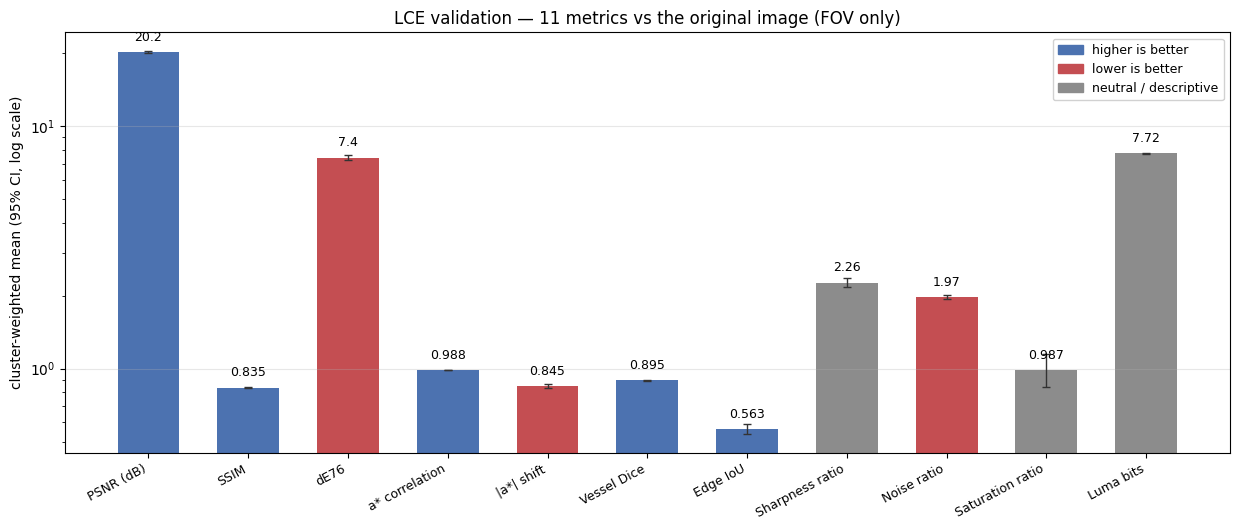

Saved results\lce_metric_summary.png

All validation artefacts written:
  results\Book1(AutoRecovered).xlsx
  results\SRR_threshold_sweep.csv
  results\SRR_validation_table_A.csv
  results\SRR_validation_table_B.csv
  results\clahe_metric_distributions.png
  results\clahe_preview.png
  results\clahe_validation_metrics.csv
  results\clahe_validation_results.json
  results\clahe_validation_summary.csv
  results\color_constancy_before_after.png
  results\fig_W_config_comparison.png
  results\fig_before_after.png
  results\fig_metric_bars.png
  results\fig_metric_smallmultiples.png
  results\identity_reference_metrics.csv
  results\lce_before_after.png
  results\lce_metric_summary.png
  results\lce_validation_metrics.csv
  results\lce_validation_summary.csv
  results\masks
  results\per_image_metrics.csv
  results\results_CannyEdge.csv
  results\results_Identity.csv
  results\results_ROI-Extraction.csv
  results\srr_mask_0000.png
  results\srr_mask_0001.png
  results\srr_mask_0002.png
  re

In [13]:
# ============================================================
# Step 4.8 -- Figure: 11-metric summary bar chart for LCE.
#             (The before/after grid was saved in Part A, cell 1.4.)
# ============================================================
fig, ax = plt.subplots(figsize=(12.5, 5.4))
means = [float(agg_df.loc["LCE", mk]) for mk in METRIC_KEYS]
err_lo = [float(agg_df.loc["LCE", mk] - agg_df.loc["LCE", f"{mk}_lo"])
          for mk in METRIC_KEYS]
err_hi = [float(agg_df.loc["LCE", f"{mk}_hi"] - agg_df.loc["LCE", mk])
          for mk in METRIC_KEYS]
names = [METRIC_NAMES[mk] for mk in METRIC_KEYS]
colors = ['#4C72B0' if METRIC_BETTER[mk] == 'up' else
          '#C44E52' if METRIC_BETTER[mk] == 'down' else
          '#8C8C8C' for mk in METRIC_KEYS]

# Log scale cannot draw zero-height bars: plot at a small floor and
# annotate the TRUE value instead.
_FLOOR = 1e-3
plot_h = [max(v, _FLOOR) for v in means]
ax.bar(range(len(plot_h)), plot_h, color=colors, width=0.62)
ax.errorbar(range(len(plot_h)), plot_h,
            yerr=[err_lo, err_hi],
            fmt='none', ecolor='#333333', elinewidth=1.0, capsize=3)
for x, v in zip(range(len(means)), means):
    ax.annotate(f"{v:.3g}", (x, max(v, _FLOOR)), ha='center', va='bottom',
                fontsize=9, xytext=(0, 6), textcoords='offset points')
ax.set_xticks(range(len(names)))
ax.set_xticklabels(names, rotation=28, ha='right', fontsize=9)
ax.set_ylabel("cluster-weighted mean (95% CI, log scale)")
ax.set_yscale('log')
ax.set_title("LCE validation — 11 metrics vs the original image (FOV only)")
ax.grid(axis='y', alpha=0.3)
ax.legend(handles=[Patch(color='#4C72B0', label='higher is better'),
                   Patch(color='#C44E52', label='lower is better'),
                   Patch(color='#8C8C8C', label='neutral / descriptive')],
          loc='best', fontsize=9, framealpha=0.9)
fig.tight_layout()
_fig_csv = os.path.join(SAVE_DIR, "lce_metric_summary.png")
fig.savefig(_fig_csv, dpi=110)
plt.show()
print(f"Saved {_fig_csv}")

print("\nAll validation artefacts written:")
for _f in sorted(os.listdir(SAVE_DIR)):
    print(f"  {os.path.join(SAVE_DIR, _f)}")
